<a href="https://colab.research.google.com/github/Angelinat3/Machine-Learning2026/blob/main/JS06/JS06_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [2]:
# create a funtion to display model fitting

def plot_svc_decision_function(model, ax=None, plot_support=True):

  if ax is None:
    ax = plt.gca()
  xlim = ax.get_xlim()
  ylim = ax.get_ylim()

  # create a grid for model evaluation
  x = np.linspace(xlim[0], xlim[1], 30)
  y = np.linspace(ylim[0], ylim[1], 30)
  Y, X = np.meshgrid(y, x)
  xy = np.vstack([X.ravel(), Y.ravel()]).T
  P = model.decision_function(xy).reshape(X.shape)

  # plot boundary and margins
  ax.contour(X, Y, P, colors='k',
             levels=[-1, 0, 1], alpha=0.5,
             linestyles=['--', '-', '--'])

  # plot support vectors
  if plot_support:
      ax.scatter(model.support_vectors_[:, 0],
                 model.support_vectors_[:, 1],
                 s=300, linewidth=1, facecolors='none');
  ax.set_xlim(xlim)
  ax.set_ylim(ylim)

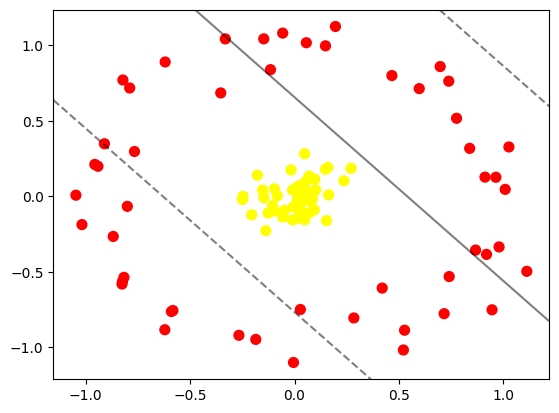

In [3]:
# example of non-linearly separable data
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [4]:
r = np.exp(-(X**2).sum(1))

In [5]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.59292560e-01,  1.91795324e-01],
       [ 9.67232337e-03,  5.86422654e-02],
       [-9.56456349e-01,  2.11294877e-01],
       [-1.26981169e-01, -1.10951415e-01],
       [ 2.83963062e-01, -8.05448925e-01],
       [ 4.15081298e-02,  7.93898505e-02],
       [ 1.00894766e+00,  4.60540995e-02],
       [ 1.38297306e-02, -2.36940366e-02],
       [ 2.83323975e-02, -4.41904475e-02],
       [ 1.02674714e+00,  3.26898596e-01],
       [-8.00957923e-01, -6.63284664e-02],
       [ 9.45881570e-01, -7.51346058e-01],
       [-5.67748921e-02,  1.08101397e+00],
       [ 4.66151179e-01,  7.99741942e-01],
       [ 9.79514985e-01, -3.34961115e-01],
       [ 3.19639007e-02, -9.80003721e-02],
       [-1.67438632e-02,  1.74882971e-01],
       [ 8.56672777e-02, -1.79552211e-02],
       [ 7.68661461e-02, -2.49615681e-03],
       [ 6.99872385e-02,  1.34138473e-01],
       [ 9.12117040e-01,  1.27138248e-01],
       [-6.21281877e-01, -8.83358310e-01],
       [ 1.11239719e+00, -4.96473596e-01],
       [ 2.77964231e-02, -7.49283222e-01],
       [ 2.93079933e-02, -1.54629274e-02],
       [ 5.97212902e-01,  7.13338764e-01],
       [-8.68494193e-01, -2.65628013e-01],
       [ 5.53071740e-02,  9.99746927e-02],
       [ 2.34092376e-02, -1.44049917e-01],
       [-1.46231644e-01, -9.61321870e-03],
       [ 5.26877751e-01, -8.86414651e-01],
       [ 1.48131878e-01,  9.96672448e-01],
       [-5.89921582e-01, -7.62817953e-01],
       [-3.53475439e-01,  6.84763231e-01],
       [-9.63452264e-02,  4.98462699e-02],
       [ 7.16523280e-01, -7.76996764e-01],
       [-4.80174156e-02, -9.24033177e-02],
       [-1.15200086e-01,  8.38789494e-01],
       [-3.31593312e-01,  1.04250355e+00],
       [-5.09904902e-03, -6.86204116e-02],
       [-1.37683228e-01, -2.27795315e-01],
       [-7.89588042e-01,  7.17523933e-01],
       [-9.10636650e-01,  3.48154448e-01],
       [-7.66532965e-01,  2.96925527e-01],
       [ 6.35399860e-02, -1.13920643e-02],
       [-1.52887231e-01,  4.13385757e-02],
       [-1.04731196e+00,  7.65443334e-03],
       [ 4.79869270e-02,  2.82290636e-01],
       [ 1.95874179e-01,  1.12480919e+00],
       [ 2.36003966e-01,  1.03088845e-01],
       [-1.01837457e+00, -1.87266042e-01],
       [ 9.72441243e-02,  1.12957521e-01],
       [-2.66474278e-01, -9.20180856e-01],
       [-8.17127165e-01, -5.36543913e-01],
       [ 1.73565233e-02,  4.70903790e-03],
       [-6.19642085e-01,  8.89733590e-01],
       [ 7.40543248e-01, -5.31364035e-01],
       [ 4.86364042e-02, -1.55222083e-01],
       [ 5.21400790e-01, -1.01762267e+00],
       [-5.05696397e-03, -1.10020073e+00],
       [-5.82585081e-01, -7.56076281e-01],
       [ 1.01164028e-01,  4.27682148e-02],
       [ 1.53055703e-01, -1.60936595e-01],
       [ 7.76010866e-01,  5.16830675e-01],
       [ 6.97509934e-01,  8.59408290e-01],
       [ 4.19780473e-01, -6.07498775e-01],
       [ 7.38684105e-01,  7.62609333e-01],
       [ 9.19436784e-01, -3.84564674e-01],
       [-1.85651674e-01, -9.47405231e-01],
       [-1.03532280e-01, -7.63617026e-02],
       [-5.61979964e-02, -1.37291084e-01],
       [ 9.64176778e-01,  1.26288824e-01],
       [ 1.63452706e-01,  9.74965822e-03],
       [ 1.77745777e-02, -8.94057148e-02],
       [-8.24682954e-02,  3.40277416e-03],
       [ 1.48173121e-01,  1.79566268e-01],
       [-2.49338391e-01, -2.06290401e-02],
       [ 6.98855765e-02, -1.09764006e-01],
       [ 8.15663638e-02, -2.18358532e-03],
       [ 8.66987734e-01, -3.56018078e-01],
       [-1.47581852e-01,  1.04284603e+00],
       [-1.78211408e-01,  1.39844982e-01],
       [ 7.54210809e-02, -3.48572801e-02],
       [-9.41693345e-01,  1.99019497e-01],
       [ 9.49006931e-02, -8.90801327e-02],
       [ 6.41310145e-02,  2.99529928e-02],
       [-2.05177096e-01, -1.22780086e-01],
       [ 2.70681074e-01,  1.85823854e-01],
       [ 8.38877002e-01,  3.17758349e-01],
       [-9.48915195e-03,  4.19869204e-02],
       [-8.26519724e-01, -5.80667339e-01],
       [-9.51226890e-03, -1.55698876e-01

In [6]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

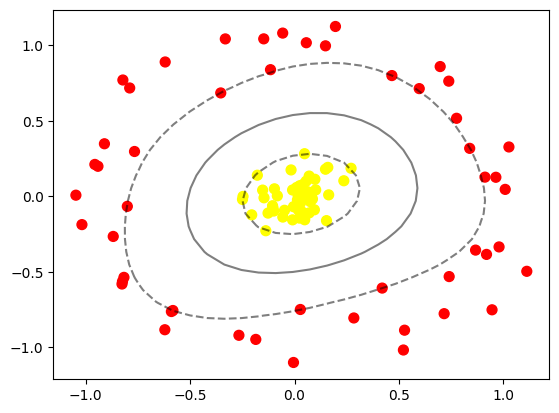

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')